# Entrega final – Estimación de la etiqueta LUNG_CANCER con aprendizaje automático
**Minería de Datos – Proyecto de aula (corte 3)** · Universidad de la Costa

Notebook final, ejecutado de principio a fin. Flujo: carga y limpieza → EDA → comparación de cinco modelos (resultados del segundo avance, reproducidos) → ajuste de hiperparámetros y umbral (cambios del tercer corte) → evaluación final → estabilidad con otras particiones → serialización del pipeline y prueba de consistencia con la aplicación de Streamlit.

> Prototipo académico: el resultado no es un diagnóstico médico.

In [1]:
import warnings, json, os
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, scipy, joblib
from scipy.stats import fisher_exact, mannwhitneyu
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_validate, GridSearchCV)
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report, precision_recall_fscore_support,
                             make_scorer, recall_score)
from utils import FEATURES, FEATURES_BIN, LABELS_ES, TARGET, load_clean   # misma limpieza que usa la app

sns.set_theme(style="whitegrid")
SEED = 42
print("Python / pandas / numpy / scipy / scikit-learn:", pd.__version__, np.__version__, scipy.__version__, sklearn.__version__)

Python / pandas / numpy / scipy / scikit-learn: 3.0.6 2.5.4 1.18.1 1.9.1


## 1. Datos: carga, limpieza y versión final

In [2]:
DATA_PATH = "data/survey lung cancer.csv"
df_raw = pd.read_csv(DATA_PATH)
print("Dimensiones originales:", df_raw.shape)
print("Distribución original:", df_raw["LUNG_CANCER"].str.strip().value_counts().to_dict())
print("Valores faltantes:", int(df_raw.isna().sum().sum()), "| Duplicados:", int(df_raw.duplicated().sum()))

# Limpieza compartida con la app: nombres sin espacios, sin duplicados,
# GENDER M=1/F=0, binarias 1/2 -> 0/1 y objetivo YES=1/NO=0
df = load_clean(DATA_PATH)
print("Dimensiones finales:", df.shape, "| distribución final (NO, YES):", df[TARGET].value_counts().sort_index().tolist())
display(df.head())

# Valores atípicos de la edad (regla 1,5·IQR)
q1, q3 = df["AGE"].quantile([.25, .75]); iqr = q3 - q1
lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
print(f"Límites IQR de edad: [{lo:.1f}, {hi:.1f}] | edades atípicas:", sorted(df.loc[(df.AGE < lo) | (df.AGE > hi), "AGE"].tolist()))

Dimensiones originales: (309, 16)
Distribución original: {'YES': 270, 'NO': 39}
Valores faltantes: 0 | Duplicados: 33
Dimensiones finales: (276, 16) | distribución final (NO, YES): [38, 238]


,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN,LUNG_CANCER
0,1,69,0,1,1,0,0,1,0,1,1,1,1,1,1,1
1,1,74,1,0,0,0,1,1,1,0,0,0,1,1,1,1
2,0,59,0,0,0,1,0,1,0,1,0,1,1,0,1,0
3,1,63,1,1,1,0,0,0,0,0,1,0,0,1,1,0
4,0,63,0,1,0,0,0,0,0,1,0,1,1,0,0,0


Límites IQR de edad: [40.9, 85.9] | edades atípicas: [21, 38, 39, 87]


## 2. Análisis exploratorio

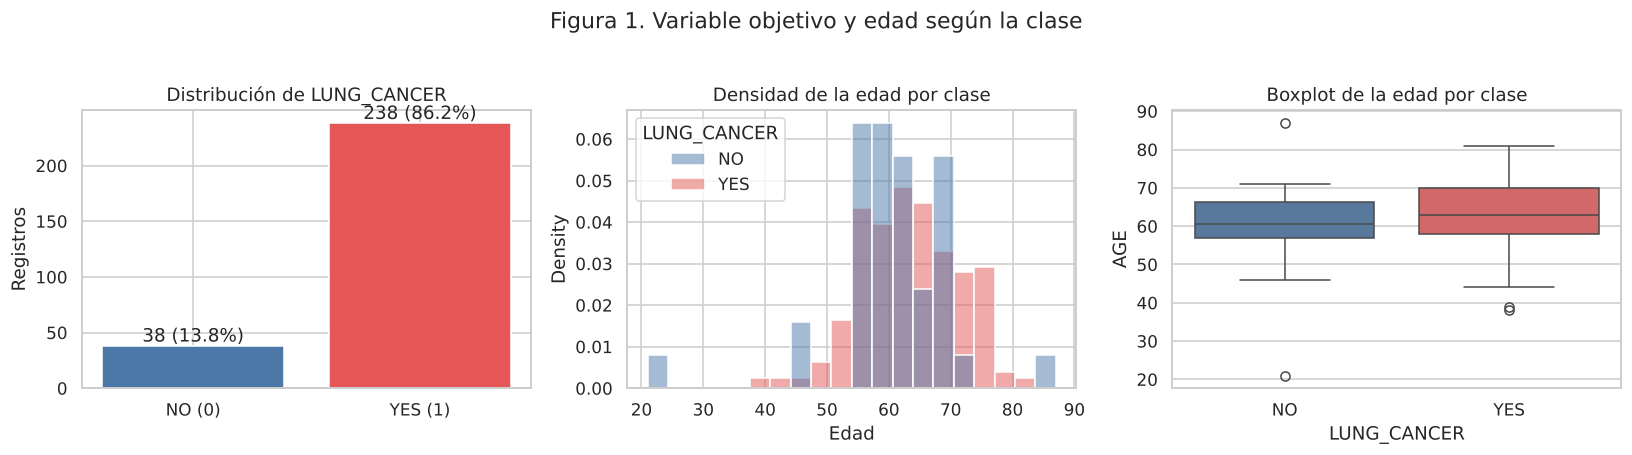

Razón YES:NO = 6.3 a 1 | accuracy de 'responder siempre YES' = 0.862
Edad media YES 63.3 (mediana 63.0, desv. 8.11) | NO 60.7 (mediana 60.5, desv. 9.75)
Mann-Whitney p = 0.11


In [3]:
n = len(df); counts = df[TARGET].value_counts().sort_index()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(["NO (0)", "YES (1)"], counts.values, color=["#4c78a8", "#e45756"])
for i, v in enumerate(counts.values): axes[0].text(i, v, f"{v} ({v/n:.1%})", ha="center", va="bottom")
axes[0].set_title("Distribución de LUNG_CANCER"); axes[0].set_ylabel("Registros")
clase = df[TARGET].map({0: "NO", 1: "YES"})
sns.histplot(x=df["AGE"], hue=clase, stat="density", common_norm=False, ax=axes[1], hue_order=["NO", "YES"], palette=["#4c78a8", "#e45756"])
axes[1].set_title("Densidad de la edad por clase"); axes[1].set_xlabel("Edad")
sns.boxplot(x=clase, y=df["AGE"], order=["NO", "YES"], palette=["#4c78a8", "#e45756"], ax=axes[2])
axes[2].set_title("Boxplot de la edad por clase"); axes[2].set_xlabel("LUNG_CANCER")
plt.suptitle("Figura 1. Variable objetivo y edad según la clase", y=1.03); plt.tight_layout(); plt.show()

a, b = df.loc[df[TARGET] == 1, "AGE"], df.loc[df[TARGET] == 0, "AGE"]
print(f"Razón YES:NO = {counts[1]/counts[0]:.1f} a 1 | accuracy de 'responder siempre YES' = {counts[1]/n:.3f}")
print(f"Edad media YES {a.mean():.1f} (mediana {a.median():.1f}, desv. {a.std():.2f}) | NO {b.mean():.1f} (mediana {b.median():.1f}, desv. {b.std():.2f})")
print("Mann-Whitney p =", round(mannwhitneyu(a, b).pvalue, 3))

Tabla 2. Frecuencia de cada característica por clase y prueba exacta de Fisher


,Variable,% con la caract. (YES),% con la caract. (NO),Odds ratio,p (Fisher),Dif. (pp)
0,Alergia,61.345,13.158,10.474,0.000,48.187
1,Consumo de alcohol,60.924,18.421,6.905,0.000,42.503
2,Dificultad para tragar,52.101,13.158,7.179,0.000,38.943
3,Tos,62.605,26.316,4.688,0.000,36.289
4,Sibilancias,59.664,23.684,4.766,0.000,35.980
5,Presión de grupo,54.622,26.316,3.370,0.001,28.306
6,Dolor de pecho,59.664,31.579,3.205,0.001,28.085
7,Dedos amarillos,61.345,34.211,3.052,0.002,27.134
8,Fatiga,69.328,47.368,2.511,0.010,21.959
9,Ansiedad,52.521,31.579,2.397,0.022,20.942


Variables con p < 0,05: 11 de 14 | tras Bonferroni (0,05/14 = 0.0036 ): 8


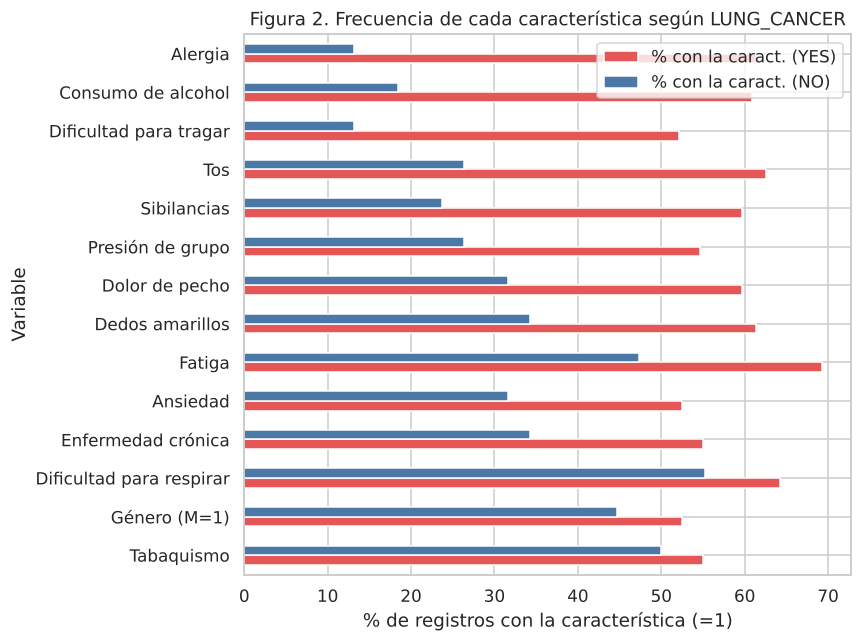

In [4]:
rows = []
for f in ["GENDER"] + FEATURES_BIN:
    A = int(((df[f] == 1) & (df[TARGET] == 1)).sum()); B = int(((df[f] == 0) & (df[TARGET] == 1)).sum())
    C = int(((df[f] == 1) & (df[TARGET] == 0)).sum()); D = int(((df[f] == 0) & (df[TARGET] == 0)).sum())
    orr, p = fisher_exact([[A, B], [C, D]])
    rows.append({"Variable": LABELS_ES.get(f, "Género (M=1)"), "% con la caract. (YES)": 100*A/(A+B),
                 "% con la caract. (NO)": 100*C/(C+D), "Odds ratio": orr, "p (Fisher)": p})
tab2 = pd.DataFrame(rows)
tab2["Dif. (pp)"] = tab2["% con la caract. (YES)"] - tab2["% con la caract. (NO)"]
tab2 = tab2.sort_values("Dif. (pp)", ascending=False).reset_index(drop=True)
print("Tabla 2. Frecuencia de cada característica por clase y prueba exacta de Fisher")
display(tab2.round(3))
print("Variables con p < 0,05:", int((tab2["p (Fisher)"] < 0.05).sum()), "de", len(tab2),
      "| tras Bonferroni (0,05/14 =", round(0.05/14, 4), "):", int((tab2["p (Fisher)"] < 0.05/14).sum()))

plot = tab2.set_index("Variable")[["% con la caract. (YES)", "% con la caract. (NO)"]].iloc[::-1]
ax = plot.plot.barh(figsize=(8, 6), color=["#e45756", "#4c78a8"])
ax.set_xlabel("% de registros con la característica (=1)"); ax.set_title("Figura 2. Frecuencia de cada característica según LUNG_CANCER")
plt.tight_layout(); plt.show()

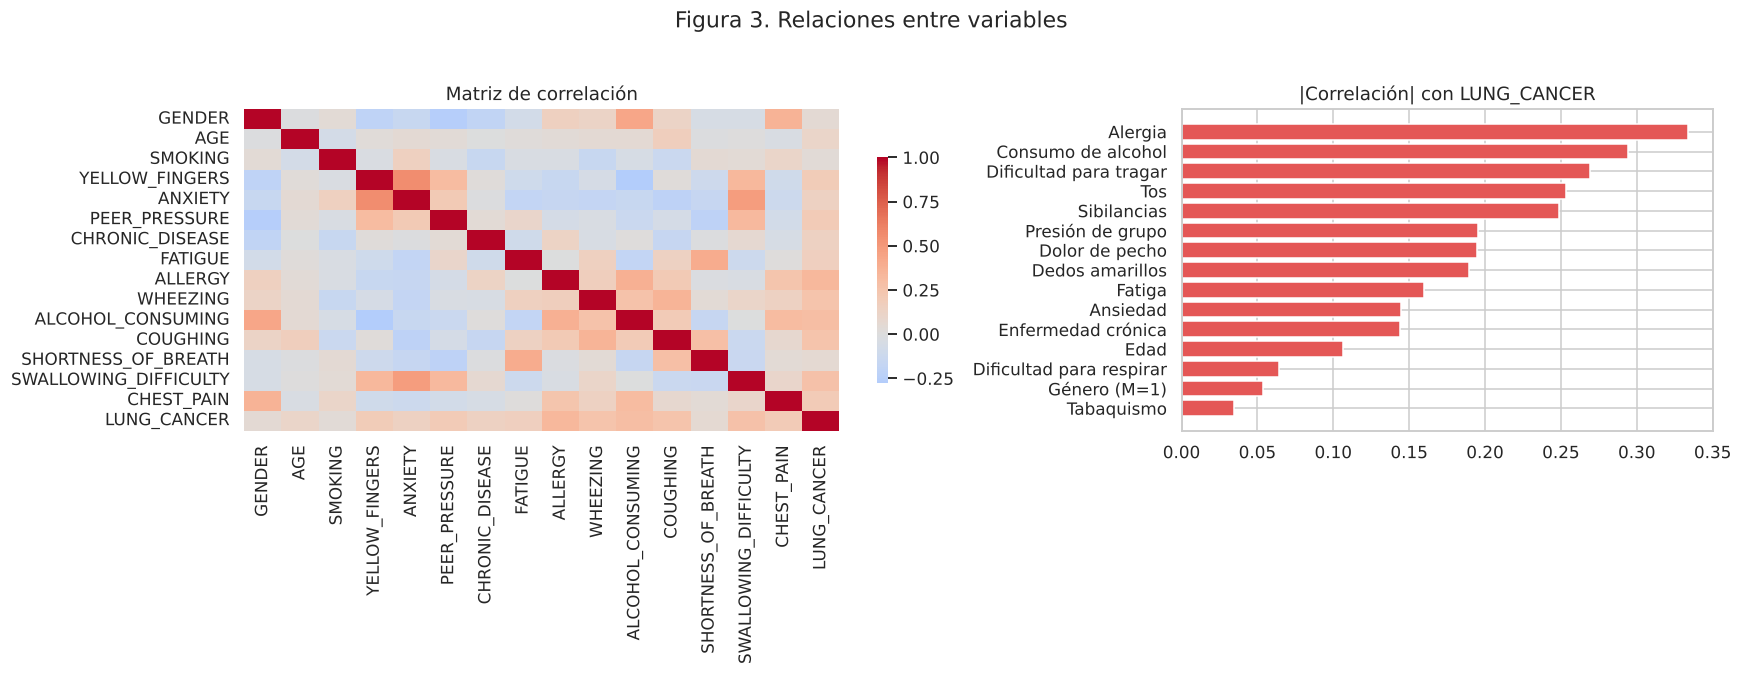

Mayores correlaciones entre predictoras:
YELLOW_FINGERS  ANXIETY                  0.56
ANXIETY         SWALLOWING_DIFFICULTY    0.48
GENDER          ALCOHOL_CONSUMING        0.43
dtype: float64
Mayores correlaciones con la etiqueta:
ALLERGY                  0.33
ALCOHOL_CONSUMING        0.29
SWALLOWING_DIFFICULTY    0.27
Name: LUNG_CANCER, dtype: float64


In [5]:
corr = df[FEATURES + [TARGET]].corr()
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(corr, cmap="coolwarm", center=0, ax=axes[0], cbar_kws={"shrink": .7}); axes[0].set_title("Matriz de correlación")
cl = corr[TARGET].drop(TARGET).abs().sort_values()
axes[1].barh([LABELS_ES.get(i, "Género (M=1)" if i == "GENDER" else "Edad") for i in cl.index], cl.values, color="#e45756")
axes[1].set_title("|Correlación| con LUNG_CANCER")
plt.suptitle("Figura 3. Relaciones entre variables", y=1.02); plt.tight_layout(); plt.show()
pp = corr.loc[FEATURES, FEATURES].where(np.triu(np.ones((len(FEATURES),)*2), 1).astype(bool)).stack().sort_values(ascending=False)
print("Mayores correlaciones entre predictoras:"); print(pp.head(3).round(2))
print("Mayores correlaciones con la etiqueta:"); print(corr[TARGET].drop(TARGET).sort_values(ascending=False).head(3).round(2))

## 3. División de datos y comparación de cinco modelos (configuración del segundo avance)

Entrenamiento: (220, 15) [30, 190] (NO, YES) | Prueba: (56, 15) [8, 48]
Tabla 3. Métricas globales en prueba (FN: YES clasificado como NO; FP: NO clasificado como YES)


,Accuracy,Balanced acc.,F1 macro,ROC-AUC,FN,FP
Regresión logística,0.911,0.740,0.782,0.945,1.0,4.0
Regresión logística (balanced),0.875,0.927,0.809,0.958,7.0,0.0
Árbol de decisión,0.911,0.844,0.827,0.960,3.0,2.0
KNN (k=5),0.875,0.615,0.647,0.882,1.0,6.0
SVM (RBF),0.857,0.604,0.627,0.938,2.0,6.0


Tabla 4. Métricas por clase en prueba


,Precision NO,Recall NO,F1 NO,Precision YES,Recall YES,F1 YES
Regresión logística,0.800,0.50,0.615,0.922,0.979,0.949
Regresión logística (balanced),0.533,1.00,0.696,1.000,0.854,0.921
Árbol de decisión,0.667,0.75,0.706,0.957,0.938,0.947
KNN (k=5),0.667,0.25,0.364,0.887,0.979,0.931
SVM (RBF),0.500,0.25,0.333,0.885,0.958,0.920


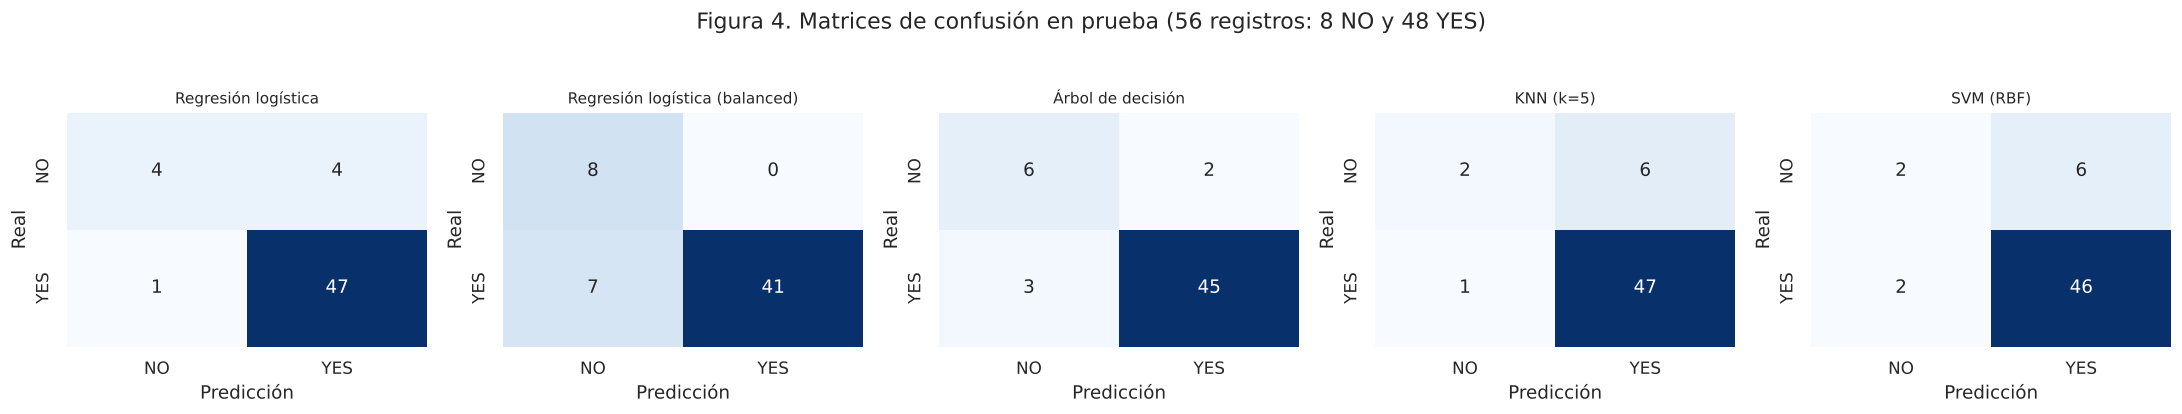

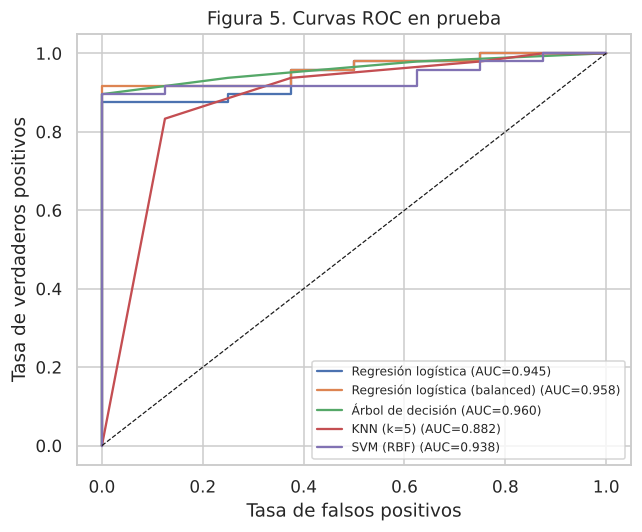

In [6]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Entrenamiento:", X_train.shape, y_train.value_counts().sort_index().tolist(), "(NO, YES) | Prueba:", X_test.shape, y_test.value_counts().sort_index().tolist())

def prep():   # solo AGE se estandariza; el escalador se ajusta únicamente con entrenamiento (dentro del Pipeline)
    return ColumnTransformer([("age", StandardScaler(), ["AGE"])], remainder="passthrough")
def make_pipe(clf): return Pipeline([("prep", prep()), ("clf", clf)])

models = {
    "Regresión logística": LogisticRegression(max_iter=1000),
    "Regresión logística (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": SVC(kernel="rbf"),
}
pipes = {k: make_pipe(m).fit(X_train, y_train) for k, m in models.items()}

def score(p, X_):
    return p.predict_proba(X_)[:, 1] if hasattr(p, "predict_proba") else p.decision_function(X_)

def row(y_true, pred, sc):
    pr, rc, f1, _ = precision_recall_fscore_support(y_true, pred, labels=[0, 1], zero_division=0)
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    return {"Accuracy": accuracy_score(y_true, pred), "Balanced acc.": balanced_accuracy_score(y_true, pred),
            "F1 macro": f1_score(y_true, pred, average="macro"), "ROC-AUC": roc_auc_score(y_true, sc),
            "FN": int(cm[1, 0]), "FP": int(cm[0, 1]),
            "Precision NO": pr[0], "Recall NO": rc[0], "F1 NO": f1[0], "Precision YES": pr[1], "Recall YES": rc[1], "F1 YES": f1[1]}

pred = {k: p.predict(X_test) for k, p in pipes.items()}
res = pd.DataFrame({k: row(y_test, pred[k], score(p, X_test)) for k, p in pipes.items()}).T
print("Tabla 3. Métricas globales en prueba (FN: YES clasificado como NO; FP: NO clasificado como YES)")
display(res[["Accuracy", "Balanced acc.", "F1 macro", "ROC-AUC", "FN", "FP"]].round(3))
print("Tabla 4. Métricas por clase en prueba")
display(res[["Precision NO", "Recall NO", "F1 NO", "Precision YES", "Recall YES", "F1 YES"]].round(3))

fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, (k, p) in zip(axes, pipes.items()):
    sns.heatmap(confusion_matrix(y_test, pred[k], labels=[0, 1]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["NO", "YES"], yticklabels=["NO", "YES"]); ax.set_title(k, fontsize=10); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
plt.suptitle("Figura 4. Matrices de confusión en prueba (56 registros: 8 NO y 48 YES)", y=1.04); plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 5))
for k, p in pipes.items():
    fpr, tpr, _ = roc_curve(y_test, score(p, X_test)); plt.plot(fpr, tpr, label=f"{k} (AUC={res.loc[k, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=.8); plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Tasa de verdaderos positivos")
plt.title("Figura 5. Curvas ROC en prueba"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

In [7]:
tt = pd.DataFrame({"Accuracy entrenamiento": {k: accuracy_score(y_train, p.predict(X_train)) for k, p in pipes.items()},
                   "Accuracy prueba": {k: accuracy_score(y_test, pred[k]) for k in pipes}})
tt["Diferencia"] = tt.iloc[:, 0] - tt.iloc[:, 1]
print("Tabla 5. Accuracy en entrenamiento y prueba"); display(tt.round(3))

cv5x3 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
scoring = {"Accuracy": "accuracy", "Balanced acc.": "balanced_accuracy", "F1 macro": "f1_macro", "ROC-AUC": "roc_auc",
           "Recall NO": make_scorer(recall_score, pos_label=0), "Recall YES": make_scorer(recall_score, pos_label=1)}
cvres = {}
for k, m in models.items():
    r = cross_validate(make_pipe(m), X_train, y_train, cv=cv5x3, scoring=scoring)
    cvres[k] = {n: f"{r['test_'+n].mean():.3f} ± {r['test_'+n].std():.3f}" for n in scoring}
print("Tabla 6. Validación cruzada 5x3 sobre entrenamiento (media ± desviación estándar)"); display(pd.DataFrame(cvres).T)

Tabla 5. Accuracy en entrenamiento y prueba


,Accuracy entrenamiento,Accuracy prueba,Diferencia
Regresión logística,0.932,0.911,0.021
Regresión logística (balanced),0.886,0.875,0.011
Árbol de decisión,0.918,0.911,0.007
KNN (k=5),0.909,0.875,0.034
SVM (RBF),0.941,0.857,0.084


Tabla 6. Validación cruzada 5x3 sobre entrenamiento (media ± desviación estándar)


,Accuracy,Balanced acc.,F1 macro,ROC-AUC,Recall NO,Recall YES
Regresión logística,0.908 ± 0.044,0.741 ± 0.095,0.770 ± 0.102,0.926 ± 0.043,0.511 ± 0.187,0.970 ± 0.043
Regresión logística (balanced),0.838 ± 0.043,0.803 ± 0.059,0.731 ± 0.050,0.928 ± 0.043,0.756 ± 0.134,0.851 ± 0.057
Árbol de decisión,0.855 ± 0.046,0.682 ± 0.082,0.683 ± 0.079,0.758 ± 0.096,0.444 ± 0.179,0.919 ± 0.058
KNN (k=5),0.880 ± 0.041,0.669 ± 0.071,0.696 ± 0.081,0.819 ± 0.090,0.378 ± 0.142,0.960 ± 0.046
SVM (RBF),0.886 ± 0.033,0.658 ± 0.046,0.695 ± 0.056,0.877 ± 0.061,0.344 ± 0.096,0.972 ± 0.040


## 4. Cambios del tercer corte: ajuste de hiperparámetros y umbral de decisión
Se mantiene la regresión logística como familia de modelo (interpretable, mejor estabilidad en validación cruzada en el avance 2). Cambios: (i) búsqueda de `C` y `class_weight` con validación cruzada 5×3 **solo sobre entrenamiento** y balanced accuracy como criterio; (ii) elección del umbral con predicciones de validación cruzada **solo sobre entrenamiento**, exigiendo recall de YES ≥ 0,90 y maximizando el recall de NO; (iii) el conjunto de prueba se usa una única vez.

Resultados de la búsqueda (balanced accuracy CV, entrenamiento):


,param_clf__C,param_clf__class_weight,mean_test_score,std_test_score,rank_test_score
1,0.01,balanced,0.852,0.067,1
3,0.10,balanced,0.829,0.050,2
5,1.00,balanced,0.803,0.059,3
7,10.00,balanced,0.797,0.074,4
9,100.00,balanced,0.785,0.079,5
8,100.00,NaN,0.778,0.101,6


Mejores parámetros: {'clf__C': 0.01, 'clf__class_weight': 'balanced'} | balanced acc. CV: 0.852 ± 0.067
Tabla 7. Recall por clase según el umbral (validación cruzada sobre entrenamiento)


,umbral,recall_YES,recall_NO
0,0.30,1.000,0.000
1,0.35,1.000,0.000
2,0.40,0.995,0.033
3,0.45,0.963,0.433
4,0.50,0.874,0.833
5,0.55,0.547,0.933
6,0.60,0.153,1.000
7,0.65,0.026,1.000
8,0.70,0.000,1.000


Umbral elegido: 0.45


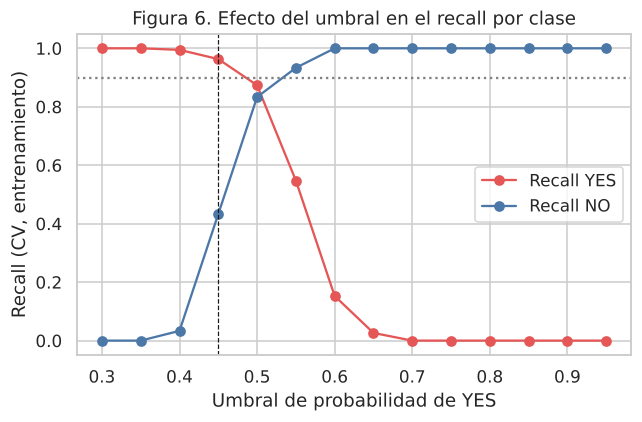

In [8]:
MIN_RECALL_YES = 0.90
grid = {"clf__C": [0.01, 0.1, 1, 10, 100], "clf__class_weight": [None, "balanced"]}
gs = GridSearchCV(make_pipe(LogisticRegression(max_iter=1000)), grid, scoring="balanced_accuracy", cv=cv5x3).fit(X_train, y_train)
best = gs.best_estimator_
cvr = pd.DataFrame(gs.cv_results_)[["param_clf__C", "param_clf__class_weight", "mean_test_score", "std_test_score", "rank_test_score"]]
print("Resultados de la búsqueda (balanced accuracy CV, entrenamiento):"); display(cvr.sort_values("rank_test_score").round(3).head(6))
print("Mejores parámetros:", gs.best_params_, "| balanced acc. CV: %.3f ± %.3f" % (gs.best_score_, gs.cv_results_["std_test_score"][gs.best_index_]))

proba_cv = cross_val_predict(best, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
trows = []
for t in np.arange(0.30, 0.951, 0.05):
    pr_ = (proba_cv >= t).astype(int)
    trows.append({"umbral": round(float(t), 2), "recall_YES": ((pr_ == 1) & (y_train == 1)).sum() / (y_train == 1).sum(),
                  "recall_NO": ((pr_ == 0) & (y_train == 0)).sum() / (y_train == 0).sum()})
thr_table = pd.DataFrame(trows)
ok = thr_table[thr_table["recall_YES"] >= MIN_RECALL_YES]
threshold = float(ok.sort_values(["recall_NO", "umbral"], ascending=[False, True]).iloc[0]["umbral"]) if len(ok) else 0.5
print("Tabla 7. Recall por clase según el umbral (validación cruzada sobre entrenamiento)"); display(thr_table.round(3).query("umbral <= 0.70"))
print("Umbral elegido:", threshold)
plt.figure(figsize=(6, 4)); plt.plot(thr_table["umbral"], thr_table["recall_YES"], "o-", label="Recall YES", color="#e45756")
plt.plot(thr_table["umbral"], thr_table["recall_NO"], "o-", label="Recall NO", color="#4c78a8"); plt.axvline(threshold, ls="--", color="k", lw=.8)
plt.axhline(MIN_RECALL_YES, ls=":", color="gray"); plt.xlabel("Umbral de probabilidad de YES"); plt.ylabel("Recall (CV, entrenamiento)")
plt.title("Figura 6. Efecto del umbral en el recall por clase"); plt.legend(); plt.tight_layout(); plt.show()

## 5. Evaluación final en el conjunto de prueba (modelo anterior vs. modelo final)

Tabla 8. Modelo anterior y modelo final


,"Modelo anterior (umbral 0,5)",Modelo final,Final en entrenamiento
Accuracy,0.911,0.929,0.923
Balanced acc.,0.740,0.802,0.829
F1 macro,0.782,0.837,0.834
ROC-AUC,0.945,0.971,0.940
FN,1.000,1.000,8.000
FP,4.000,3.000,9.000
Precision NO,0.800,0.833,0.724
Recall NO,0.500,0.625,0.700
F1 NO,0.615,0.714,0.712
Precision YES,0.922,0.940,0.953


Línea base 'responder siempre YES' en prueba: accuracy = 0.857

Reporte de clasificación del modelo final (prueba):
              precision    recall  f1-score   support

          NO      0.833     0.625     0.714         8
         YES      0.940     0.979     0.959        48

    accuracy                          0.929        56
   macro avg      0.887     0.802     0.837        56
weighted avg      0.925     0.929     0.924        56



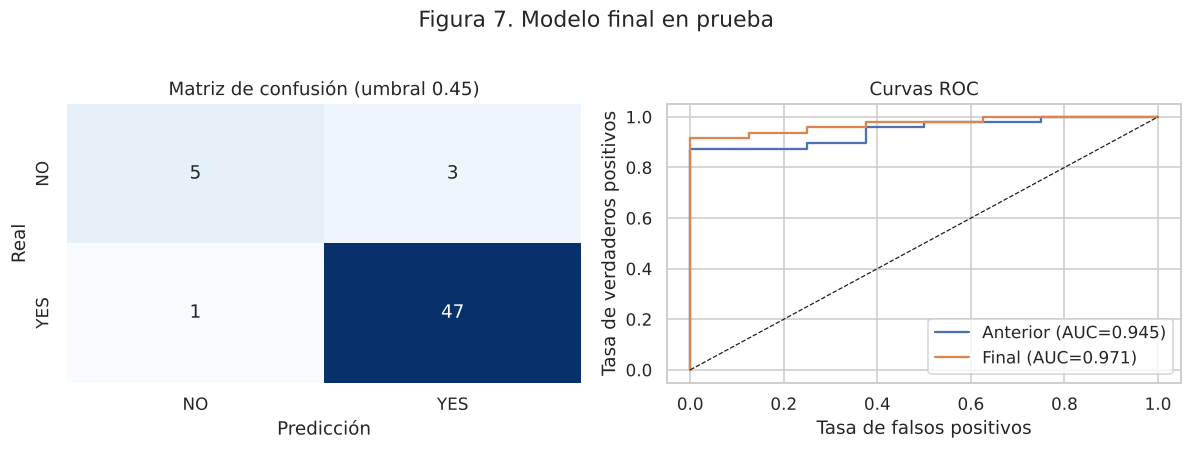

In [9]:
base = pipes["Regresión logística"]                           # modelo del avance 2: umbral 0,5
p_base = base.predict_proba(X_test)[:, 1]; p_fin = best.predict_proba(X_test)[:, 1]
r_base = row(y_test, (p_base >= 0.5).astype(int), p_base)
r_fin = row(y_test, (p_fin >= threshold).astype(int), p_fin)
r_trn = row(y_train, (best.predict_proba(X_train)[:, 1] >= threshold).astype(int), best.predict_proba(X_train)[:, 1])
comp = pd.DataFrame({"Modelo anterior (umbral 0,5)": r_base, "Modelo final": r_fin, "Final en entrenamiento": r_trn})
print("Tabla 8. Modelo anterior y modelo final"); display(comp.round(3))
print(f"Línea base 'responder siempre YES' en prueba: accuracy = {y_test.mean():.3f}")
print("\nReporte de clasificación del modelo final (prueba):")
print(classification_report(y_test, (p_fin >= threshold).astype(int), target_names=["NO", "YES"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(confusion_matrix(y_test, (p_fin >= threshold).astype(int), labels=[0, 1]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["NO", "YES"], yticklabels=["NO", "YES"]); axes[0].set_xlabel("Predicción"); axes[0].set_ylabel("Real"); axes[0].set_title(f"Matriz de confusión (umbral {threshold:.2f})")
for lbl, pp_ in [("Anterior", p_base), ("Final", p_fin)]:
    fpr, tpr, _ = roc_curve(y_test, pp_); axes[1].plot(fpr, tpr, label=f"{lbl} (AUC={roc_auc_score(y_test, pp_):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=.8); axes[1].set_xlabel("Tasa de falsos positivos"); axes[1].set_ylabel("Tasa de verdaderos positivos"); axes[1].legend(); axes[1].set_title("Curvas ROC")
plt.suptitle("Figura 7. Modelo final en prueba", y=1.02); plt.tight_layout(); plt.show()

## 6. Estabilidad con otras particiones
Se repite todo el procedimiento (partición estratificada, búsqueda de hiperparámetros, umbral con solo entrenamiento y evaluación en prueba) con 10 semillas distintas, y se compara con el modelo anterior (regresión logística, umbral 0,5).

In [10]:
def procedimiento(seed):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=seed)
    cv_ = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=seed)
    g = GridSearchCV(make_pipe(LogisticRegression(max_iter=1000)), grid, scoring="balanced_accuracy", cv=cv_).fit(Xtr, ytr)
    pcv = cross_val_predict(g.best_estimator_, Xtr, ytr, cv=StratifiedKFold(5, shuffle=True, random_state=seed), method="predict_proba")[:, 1]
    best_t, best_rno = 0.5, -1
    for t in np.arange(0.30, 0.951, 0.05):
        pr_ = (pcv >= t).astype(int)
        ry = ((pr_ == 1) & (ytr == 1)).sum() / (ytr == 1).sum(); rn = ((pr_ == 0) & (ytr == 0)).sum() / (ytr == 0).sum()
        if ry >= MIN_RECALL_YES and rn > best_rno: best_t, best_rno = round(float(t), 2), rn
    pb = make_pipe(LogisticRegression(max_iter=1000)).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
    pf = g.best_estimator_.predict_proba(Xte)[:, 1]
    out = {"semilla": seed, "umbral": best_t, "C": g.best_params_["clf__C"], "class_weight": str(g.best_params_["clf__class_weight"])}
    for nm, pp_, t in [("ant", pb, 0.5), ("fin", pf, best_t)]:
        rr = row(yte, (pp_ >= t).astype(int), pp_)
        out.update({f"BalAcc_{nm}": rr["Balanced acc."], f"RecNO_{nm}": rr["Recall NO"], f"RecYES_{nm}": rr["Recall YES"], f"F1m_{nm}": rr["F1 macro"]})
    return out
est = pd.DataFrame([procedimiento(s) for s in range(10)])
print("Tabla 9. Resultados por semilla"); display(est.round(3))
resumen = pd.DataFrame({m: {"Anterior": f"{est[m+'_ant'].mean():.3f} ± {est[m+'_ant'].std():.3f}", "Final": f"{est[m+'_fin'].mean():.3f} ± {est[m+'_fin'].std():.3f}"}
                        for m in ["BalAcc", "F1m", "RecNO", "RecYES"]}).T
resumen.index = ["Balanced accuracy", "F1 macro", "Recall NO", "Recall YES"]
print("Tabla 10. Media ± desviación estándar en 10 particiones (prueba)"); display(resumen)

Tabla 9. Resultados por semilla


,semilla,umbral,C,class_weight,BalAcc_ant,RecNO_ant,RecYES_ant,F1m_ant,BalAcc_fin,RecNO_fin,RecYES_fin,F1m_fin
0,0,0.45,0.10,balanced,0.667,0.375,0.958,0.695,0.844,0.750,0.938,0.827
1,1,0.50,0.01,balanced,0.656,0.375,0.938,0.673,0.656,0.500,0.812,0.619
2,2,0.45,0.01,balanced,0.740,0.500,0.979,0.782,0.802,0.625,0.979,0.837
3,3,0.50,0.10,balanced,0.729,0.500,0.958,0.755,0.812,0.750,0.875,0.757
4,4,0.45,1.00,balanced,0.667,0.375,0.958,0.695,0.635,0.375,0.896,0.635
5,5,0.45,0.10,balanced,0.677,0.375,0.979,0.720,0.865,0.750,0.979,0.885
6,6,0.45,0.10,balanced,0.792,0.625,0.958,0.808,0.906,0.875,0.938,0.868
7,7,0.45,0.10,balanced,0.865,0.750,0.979,0.885,0.958,1.000,0.917,0.878
8,8,0.40,0.10,balanced,0.719,0.500,0.938,0.731,0.771,0.625,0.917,0.757
9,9,0.45,0.10,balanced,0.604,0.250,0.958,0.627,0.823,0.750,0.896,0.778


Tabla 10. Media ± desviación estándar en 10 particiones (prueba)


,Anterior,Final
Balanced accuracy,0.711 ± 0.075,0.807 ± 0.101
F1 macro,0.737 ± 0.074,0.784 ± 0.095
Recall NO,0.463 ± 0.145,0.700 ± 0.179
Recall YES,0.960 ± 0.015,0.915 ± 0.050


## 7. Variables más influyentes (modelo final)

Tabla 11. Coeficientes de la regresión logística final


,Variable,Coeficiente,Odds ratio (exp coef)
0,Alergia,0.201,1.223
1,Consumo de alcohol,0.179,1.196
2,Dificultad para tragar,0.151,1.163
3,Presión de grupo,0.144,1.155
4,Enfermedad crónica,0.127,1.135
5,Sibilancias,0.124,1.132
6,Dolor de pecho,0.122,1.130
7,Tos,0.120,1.127
8,Dedos amarillos,0.120,1.127
9,Ansiedad,0.100,1.105


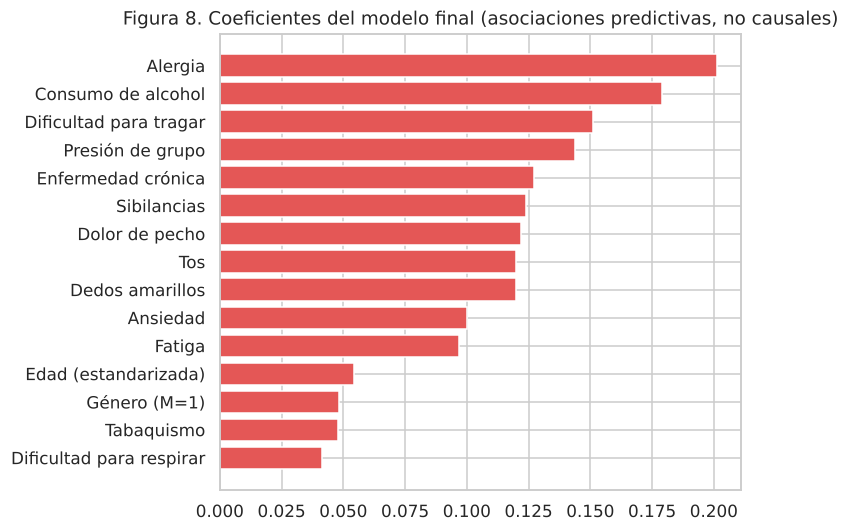

In [11]:
nombres = ["Edad (estandarizada)"] + [LABELS_ES.get(f, "Género (M=1)") for f in FEATURES if f != "AGE"]
coef = pd.DataFrame({"Variable": nombres, "Coeficiente": best.named_steps["clf"].coef_[0]})
coef["Odds ratio (exp coef)"] = np.exp(coef["Coeficiente"]); coef = coef.sort_values("Coeficiente", ascending=False).reset_index(drop=True)
print("Tabla 11. Coeficientes de la regresión logística final"); display(coef.round(3))
plt.figure(figsize=(7, 5)); plt.barh(coef["Variable"][::-1], coef["Coeficiente"][::-1], color=["#e45756" if c > 0 else "#4c78a8" for c in coef["Coeficiente"][::-1]])
plt.title("Figura 8. Coeficientes del modelo final (asociaciones predictivas, no causales)"); plt.tight_layout(); plt.show()

## 8. Serialización del pipeline y prueba de consistencia con la aplicación

In [12]:
os.makedirs("model", exist_ok=True)
joblib.dump({"pipeline": best, "threshold": threshold, "features": FEATURES}, "model/pipeline.joblib")
test_out = X_test.copy(); test_out["y_real"] = y_test; test_out["proba_YES"] = p_fin
test_out.to_csv("model/test_set_with_proba.csv", index=True)
print("Guardado: model/pipeline.joblib y model/test_set_with_proba.csv")

# Lo que hace la app: cargar el pipeline y predecir un registro construido con las mismas columnas y el mismo orden
bundle = joblib.load("model/pipeline.joblib")
pipe_app, thr_app = bundle["pipeline"], bundle["threshold"]
diff = np.abs(pipe_app.predict_proba(X_test[FEATURES])[:, 1] - p_fin).max()
print("Diferencia máxima entre probabilidades (pipeline cargado vs. notebook):", diff)
ej = X_test.iloc[[0]]
pj = float(pipe_app.predict_proba(ej[FEATURES])[0, 1])
print("Registro de prueba (índice %s):" % ej.index[0], ej.iloc[0].to_dict())
print(f"Probabilidad de YES = {pj:.4f} -> etiqueta {'YES' if pj >= thr_app else 'NO'} (real: {'YES' if y_test.iloc[0] == 1 else 'NO'})")

Guardado: model/pipeline.joblib y model/test_set_with_proba.csv
Diferencia máxima entre probabilidades (pipeline cargado vs. notebook): 0.0
Registro de prueba (índice 217): {'GENDER': 0, 'AGE': 77, 'SMOKING': 0, 'YELLOW_FINGERS': 0, 'ANXIETY': 0, 'PEER_PRESSURE': 1, 'CHRONIC_DISEASE': 1, 'FATIGUE': 1, 'ALLERGY': 1, 'WHEEZING': 1, 'ALCOHOL_CONSUMING': 1, 'COUGHING': 0, 'SHORTNESS_OF_BREATH': 0, 'SWALLOWING_DIFFICULTY': 0, 'CHEST_PAIN': 1}
Probabilidad de YES = 0.5968 -> etiqueta YES (real: YES)
